## Analysis for CCS3


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Some basic data loading and cleanup of useless columns

In [6]:
def clean_df(df: pd.DataFrame):
    df['TOI'] = df['TOI'].replace('ch3 (1)', 'ch3')
    df['TOI'] = df['TOI'].replace('ch5 (1)', 'ch5')
    df['TOI'] = df['TOI'].replace('ch7 (1)', 'ch7')
    df['TOI'] = df['TOI'].replace('ch9 (1)', 'ch9')

    df['TOI'] = df['TOI'].replace('d2 (1)', 'd2')
    df['TOI'] = df['TOI'].replace('d5 (1)', 'd5')
    df['TOI'] = df['TOI'].replace('f2 (1)', 'f2')
    df['TOI'] = df['TOI'].replace('f3 (1)', 'f3')
    df['TOI'] = df['TOI'].replace('f4 (1)', 'f4')

    df['TOI'] = df['TOI'].replace('ts_1', 'ts1')
    df['TOI'] = df['TOI'].replace('ts3 (1)', 'ts3')
    df['TOI'] = df['TOI'].replace('ts4 (1)', 'ts4')
    df['TOI'] = df['TOI'].replace('ts5 (1)', 'ts5')
    df['TOI'] = df['TOI'].replace('ts6 (1)', 'ts6')
    df['TOI'] = df['TOI'].replace('ts7 (1)', 'ts7')
    df['TOI'] = df['TOI'].replace('ts8 (1)', 'ts8')
    df['TOI'] = df['TOI'].replace('ts9 (1)', 'ts9')
    df['TOI'] = df['TOI'].replace('ts10 (1)', 'ts10')
    
    df['Media'] = df['Media'].replace('ch3 (1)', 'ch3')
    df['Media'] = df['Media'].replace('ch5 (1)', 'ch5')
    df['Media'] = df['Media'].replace('ch7 (1)', 'ch7')
    df['Media'] = df['Media'].replace('ch9 (1)', 'ch9')

    df['Media'] = df['Media'].replace('d2 (1)', 'd2')
    df['Media'] = df['Media'].replace('d5 (1)', 'd5')
    df['Media'] = df['Media'].replace('f2 (1)', 'f2')
    df['Media'] = df['Media'].replace('f3 (1)', 'f3')
    df['Media'] = df['Media'].replace('f4 (1)', 'f4')

    df['Media'] = df['Media'].replace('ts_1', 'ts1')
    df['Media'] = df['Media'].replace('ts3 (1)', 'ts3')
    df['Media'] = df['Media'].replace('ts4 (1)', 'ts4')
    df['Media'] = df['Media'].replace('ts5 (1)', 'ts5')
    df['Media'] = df['Media'].replace('ts6 (1)', 'ts6')
    df['Media'] = df['Media'].replace('ts7 (1)', 'ts7')
    df['Media'] = df['Media'].replace('ts8 (1)', 'ts8')
    df['Media'] = df['Media'].replace('ts9 (1)', 'ts9')
    df['Media'] = df['Media'].replace('ts10 (1)', 'ts10')
    
    return df.drop(columns=['Recording'])

In [7]:
df = pd.read_csv(f'metrics.tsv', sep='\t') 
df = clean_df(df)

participants = {name: df[df['Participant']==name] for name in df['Participant'].unique()}


In [8]:
part = participants['Sebastian']
part[part['TOI']=='ts1']

list(part)

['Participant',
 'TOI',
 'Interval',
 'Media',
 'AOI',
 'Duration_of_interval',
 'Start_of_interval',
 'Last_key_press',
 'Total_duration_of_whole_fixations',
 'Average_duration_of_whole_fixations',
 'Minimum_duration_of_whole_fixations',
 'Maximum_duration_of_whole_fixations',
 'Number_of_whole_fixations',
 'Time_to_first_whole_fixation',
 'Duration_of_first_whole_fixation',
 'Total_duration_of_Visit',
 'Average_duration_of_Visit',
 'Minimum_duration_of_Visit',
 'Maximum_duration_of_Visit',
 'Number_of_Visits',
 'Time_to_first_Visit',
 'Duration_of_first_Visit',
 'AOI_string',
 'Text_unit_type',
 'First-pass_regression',
 'Regression-path_duration',
 'Re-reading_duration']

In [9]:
part.columns

part['TOI'].unique()


array(['b1', 'b2', 'b3', 'b4', 'b5', 'b6', 'b7', 'b8', 'b9', 'b10', 'ch1',
       'ch2', 'ch3', 'ch4', 'ch5', 'ch6', 'ch7', 'ch8', 'ch9', 'ch10',
       'd1', 'd2', 'd3', 'd4', 'd5', 'd6', 'd7', 'd8', 'd9', 'd10', 'f1',
       'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'g1', 'g2',
       'g3', 'g4', 'g5', 'g6', 'g7', 'g8', 'g9', 'g10', 'l1', 'l2', 'l3',
       'l4', 'l5', 'l6', 'l7', 'l8', 'l9', 'l10', 'p1', 'p2', 'p3', 'p4',
       'p5', 'p6', 'p7', 'p8', 'p9', 'p10', 'qb', 'qch', 'qd', 'qf', 'qg',
       'ql', 'qp', 'qsh', 'qts', 'sh1', 'sh2', 'sh3', 'sh4', 'sh5', 'sh6',
       'sh7', 'sh8', 'sh9', 'sh10', 'ts2', 'ts3', 'ts4', 'ts5', 'ts6',
       'ts7', 'ts8', 'ts9', 'ts10', 'ts1'], dtype=object)

In [10]:
old_metrics = pd.read_csv('metrics_old.tsv', sep='\t')
jarl_old = old_metrics[old_metrics['Participant']=='Sebastian']

### Fixation duration beginning vs end

In [11]:
# get all participants
participants = {name: df[df['Participant']==name] for name in df['Participant'].unique()}

letters = ['b', 'ch', 'd', 'f', 'ts', 'l', 'p', 'sh', 'g']
cyrillic = ['б', 'ч', 'д', 'ф', 'ц', 'л', 'п', 'ш', 'г']

firsts = {letter: [] for letter in letters}
lasts = {letter: [] for letter in letters}

for participant in participants:
    part = participants[participant]
    for i, letter in enumerate(letters):
    # get all toi that equal b1 through b10
        part_letter = part[part['TOI'].str.match(f'{letter}[0-9]')]

        #order by Start_of_interval
        part_letter = part_letter.sort_values(by=['Start_of_interval'])
        # get fixation time of aoi б for its first and last occurence in jarl_b
        aoi = part_letter[part_letter['AOI']==cyrillic[i]]['Maximum_duration_of_whole_fixations']
        aoi = aoi.fillna(0)
        first_half = aoi.iloc[:len(aoi)//2].mean()
        last_half = aoi.iloc[len(aoi)//2:].mean()

        firsts[letter].append(first_half)
        lasts[letter].append(last_half)
        

# compute paired t-tests

from scipy.stats import ttest_rel

for letter in letters:
    #print means
    print(f'{letter}: {np.mean(firsts[letter])} vs {np.mean(lasts[letter])}')
    print(f'{letter}: {ttest_rel(firsts[letter], lasts[letter])}')

b: 88.35999999999999 vs 69.2
b: TtestResult(statistic=1.0566592017543388, pvalue=0.30391802114964217, df=19)
ch: 262.29999999999995 vs 215.51999999999998
ch: TtestResult(statistic=1.7391264587831021, pvalue=0.09818931624845523, df=19)
d: 178.54000000000002 vs 188.02999999999997
d: TtestResult(statistic=-0.3582669910689171, pvalue=0.724093199789084, df=19)
f: 232.85000000000005 vs 259.93
f: TtestResult(statistic=-0.6529883763901119, pvalue=0.5215875221358528, df=19)
ts: 189.83000000000004 vs 193.23999999999998
ts: TtestResult(statistic=-0.10274888861636454, pvalue=0.9192389851088688, df=19)
l: 171.76999999999998 vs 152.23999999999998
l: TtestResult(statistic=0.5138341757433567, pvalue=0.6132921126709292, df=19)
p: 183.76 vs 176.98
p: TtestResult(statistic=0.19264591507518627, pvalue=0.8492805083693745, df=19)
sh: 166.56 vs 120.93999999999998
sh: TtestResult(statistic=1.2492277816657562, pvalue=0.22675340634404179, df=19)
g: 128.63999999999996 vs 118.46999999999998
g: TtestResult(statist

In [12]:
# get all participants
participants = {name: df[df['Participant']==name] for name in df['Participant'].unique()}

letters = ['b', 'ch', 'd', 'f', 'ts', 'l', 'p', 'sh', 'g']
cyrillic = ['б', 'ч', 'д', 'ф', 'ц', 'л', 'п', 'ш', 'г']

firsts = {letter: [] for letter in letters}
lasts = {letter: [] for letter in letters}

for participant in participants:
    part = participants[participant]
    for i, letter in enumerate(letters):
    # get all toi that equal b1 through b10
        part_letter = part[part['TOI'].str.match(f'{letter}[0-9]')]

        #order by Start_of_interval
        part_letter = part_letter.sort_values(by=['Start_of_interval'])
        # get fixation time of aoi б for its first and last occurence in jarl_b
        aoi = part_letter[part_letter['AOI']==cyrillic[i]]['Number_of_whole_fixations']
        aoi = aoi.fillna(0)
        first_half = aoi.iloc[:len(aoi)//2].mean()
        last_half = aoi.iloc[len(aoi)//2:].mean()

        firsts[letter].append(first_half)
        lasts[letter].append(last_half)
        

# compute paired t-tests

from scipy.stats import ttest_rel

for letter in letters:
    #print means
    print(f'{letter}: {np.mean(firsts[letter])} vs {np.mean(lasts[letter])}')
    print(f'{letter}: {ttest_rel(firsts[letter], lasts[letter])}')

b: 0.35 vs 0.2800000000000001
b: TtestResult(statistic=1.1285379086311236, pvalue=0.27314161094473755, df=19)
ch: 1.3199999999999998 vs 1.3699999999999999
ch: TtestResult(statistic=-0.23563337181874247, pvalue=0.8162383900346984, df=19)
d: 0.9800000000000001 vs 0.8800000000000001
d: TtestResult(statistic=0.6556403384430104, pvalue=0.5199163463376022, df=19)
f: 1.13 vs 1.41
f: TtestResult(statistic=-1.1152672214693216, pvalue=0.27864399065689605, df=19)
ts: 0.7699999999999999 vs 0.7100000000000001
ts: TtestResult(statistic=0.40529634797638747, pvalue=0.6897869651115527, df=19)
l: 0.9200000000000002 vs 0.58
l: TtestResult(statistic=1.3481876957208447, pvalue=0.19345223340339185, df=19)
p: 0.8800000000000001 vs 0.8600000000000001
p: TtestResult(statistic=0.13931101440087726, pvalue=0.8906704634186213, df=19)
sh: 0.76 vs 0.45999999999999996
sh: TtestResult(statistic=1.3444742443265714, pvalue=0.1946278816754501, df=19)
g: 0.62 vs 0.54
g: TtestResult(statistic=0.46042851909872196, pvalue=0.

## regression analysis

In [13]:
#data creation for regression
correct_answers = {
    'b': '2',
    'ch': '2',
    'd': '2',
    'f': '1',
    'g': '2',
    'l': '3',
    'p': '3',
    'sh': '1',
    'ts': '1'
}

participants = {name: df[df['Participant']==name] for name in df['Participant'].unique()}

letters = ['b', 'ch', 'd', 'f', 'ts', 'l', 'p', 'sh', 'g']
cyrillic = ['б', 'ч', 'д', 'ф', 'ц', 'л', 'п', 'ш', 'г']

data_dict = {'participant' : [], 'letter': [], 'tot_fixation_duration': [], 'avg_fixation_duration': [], 'number_of_fixations': [], 'avg_time_to_first_fixation': [], 'min_duration_fixation': [], 'max_duration_fixation': [], 'regression_path_duration': [],
 'rereading_duration': [], 'outcome': []}

for participant in participants:
    part = participants[participant]
    for i, letter in enumerate(letters):
    # get all toi that equal b1 through b10
        data_dict['participant'].append(participant)
        data_dict['letter'].append(cyrillic[i])
        
        total_fixation_duration = part[part['TOI'].str.match(f'{letter}[0-9]')]['Total_duration_of_whole_fixations'].sum()
        data_dict['tot_fixation_duration'].append(total_fixation_duration)
        
        avg_fixation_duration = part[part['TOI'].str.match(f'{letter}[0-9]')]['Average_duration_of_whole_fixations'].mean()
        data_dict['avg_fixation_duration'].append(avg_fixation_duration)
        
        number_of_fixations = part[part['TOI'].str.match(f'{letter}[0-9]')]['Number_of_whole_fixations'].sum()
        data_dict['number_of_fixations'].append(number_of_fixations)
        
        avg_time_to_first_fixation = part[part['TOI'].str.match(f'{letter}[0-9]')]['Time_to_first_whole_fixation'].mean()
        data_dict['avg_time_to_first_fixation'].append(avg_time_to_first_fixation)
        
        min_duration_fixation = part[part['TOI'].str.match(f'{letter}[0-9]')]['Minimum_duration_of_whole_fixations'].min()
        data_dict['min_duration_fixation'].append(min_duration_fixation)
        
        max_duration_fixation = part[part['TOI'].str.match(f'{letter}[0-9]')]['Maximum_duration_of_whole_fixations'].max()
        data_dict['max_duration_fixation'].append(max_duration_fixation)
        
        regression_path_duration = part[part['TOI'].str.match(f'{letter}[0-9]')]['Regression-path_duration'].sum()
        data_dict['regression_path_duration'].append(regression_path_duration)
        
        rereading_duration = part[part['TOI'].str.match(f'{letter}[0-9]')]['Re-reading_duration'].sum()
        data_dict['rereading_duration'].append(rereading_duration)
        
        
        
        # get last key press
        # get last key press
        last_key = part[part['TOI'].str.match(f'q{letter}')]['Last_key_press'].iloc[-1]
        
        if last_key == correct_answers[letter]:
            data_dict['outcome'].append(1)
        else:
            data_dict['outcome'].append(0)
        
        


df_reg = pd.DataFrame(data_dict)        

In [14]:
# regression analysis

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix


# Assuming your CSV has columns like:
# 'Participant ID', 'Cyrillic Letter', 'Avg. Total Fix. Dur.', 'Avg. Num. Fix.', 'Translation Accuracy'

# Select features and target
features = ['tot_fixation_duration', 'avg_fixation_duration', 'number_of_fixations', 'avg_time_to_first_fixation', 'min_duration_fixation', 'max_duration_fixation', 'regression_path_duration',
 'rereading_duration']  # Add other features as needed
target = 'outcome'

X = df_reg[features].values
y = df_reg[target].values

# Scale features (important for logistic regression)
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # 80% train, 20% test

# 2. Train the Logistic Regression Model
# L1 Regularization
l1_model = LogisticRegression(penalty='l1', solver='liblinear', random_state=42, C=0.1) #Adjust C
l1_model.fit(X_train, y_train)

print("L1 Regularization Coefficients:")
print(dict(zip(features, l1_model.coef_[0])))

# 3. Make Predictions on the Test Set
y_pred = l1_model.predict(X_test)

# 4. Evaluate the Model
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

#Optional: Print Intercept
print("\nIntercept:")
print(l1_model.intercept_)

#Optional: Predict Probabilities
y_prob = l1_model.predict_proba(X_test)
print("\nProbabilities of the first 5 test samples:\n", y_prob[:5])


#Example of loading the model
#loaded_model = joblib.load('logistic_regression_model.pkl')
#y_pred_loaded = loaded_model.predict(X_test)

# # precent true labels
print(sum(y_test) / len(y_test))

L1 Regularization Coefficients:
{'tot_fixation_duration': 0.0, 'avg_fixation_duration': 0.0, 'number_of_fixations': -0.09915662549306642, 'avg_time_to_first_fixation': 0.0, 'min_duration_fixation': 0.0, 'max_duration_fixation': 0.0, 'regression_path_duration': 0.0, 'rereading_duration': 0.0}
Confusion Matrix:
[[ 0 10]
 [ 2 24]]

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        10
           1       0.71      0.92      0.80        26

    accuracy                           0.67        36
   macro avg       0.35      0.46      0.40        36
weighted avg       0.51      0.67      0.58        36


Intercept:
[0.14082345]

Probabilities of the first 5 test samples:
 [[0.4605364  0.5394636 ]
 [0.44143537 0.55856463]
 [0.45197346 0.54802654]
 [0.47367613 0.52632387]
 [0.49344858 0.50655142]]
0.7222222222222222


Correlation Matrix:
                            tot_fixation_duration  avg_fixation_duration  \
tot_fixation_duration                    1.000000               0.544177   
avg_fixation_duration                    0.544177               1.000000   
number_of_fixations                      0.957191               0.397280   
avg_time_to_first_fixation               0.432345              -0.005798   
min_duration_fixation                    0.054710               0.404557   
max_duration_fixation                    0.652852               0.718778   
regression_path_duration                 0.995627               0.565752   
rereading_duration                       0.951065               0.448359   

                            number_of_fixations  avg_time_to_first_fixation  \
tot_fixation_duration                  0.957191                    0.432345   
avg_fixation_duration                  0.397280                   -0.005798   
number_of_fixations                    1.000000           

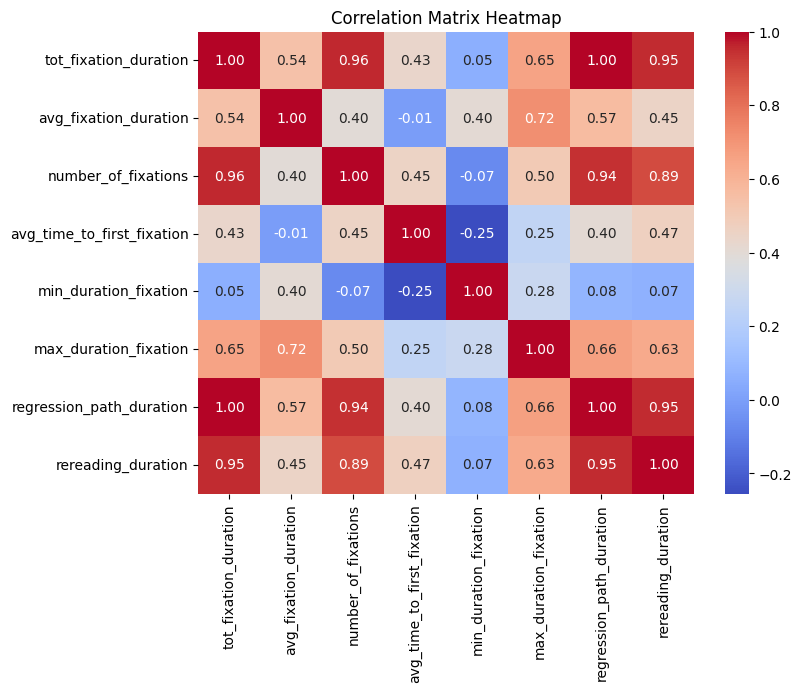

In [15]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ... (Load your data into a pandas DataFrame called 'df')

correlation_matrix = df_reg[features].corr() # features is the list of your feature names
print("Correlation Matrix:")
print(correlation_matrix)

# Visualize the correlation matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()

## Neural Network

In [16]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix


features = ['tot_fixation_duration', 'avg_fixation_duration', 'number_of_fixations', 'avg_time_to_first_fixation', 'min_duration_fixation', 'max_duration_fixation', 'regression_path_duration',
 'rereading_duration']  # Add other features as needed
target = 'outcome'

X = df_reg[features].values
y = df_reg[target].values.astype(float) # Ensure y is float for BCEWithLogitsLoss

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1) #Important reshape for BCEWithLogitsLoss
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

# 2. Define the Neural Network Model
class BinaryClassifier(nn.Module):
    def __init__(self, input_dim):
        super(BinaryClassifier, self).__init__()
        self.linear1 = nn.Linear(input_dim, 8)  # Hidden layer with 8 neurons
        self.relu = nn.ReLU()
        self.linear2 = nn.Linear(8, 1)       # Output layer with 1 neuron (for binary classification)

    def forward(self, x):
        x = self.linear1(x)
        x = self.relu(x)
        x = self.linear2(x)
        return x

input_dim = X_train.shape[1]  # Get the number of input features
model = BinaryClassifier(input_dim)

# 3. Define Loss Function and Optimizer
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy with Logits (more stable)
optimizer = optim.Adam(model.parameters(), lr=0.01) #adjust learning rate if needed

# 4. Train the Model
num_epochs = 100 #adjust number of epochs as needed
for epoch in range(num_epochs):
    # Forward pass
    outputs = model(X_train)
    loss = criterion(outputs, y_train)

    # Backward and optimize
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch+1) % 10 == 0:
        print (f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

# 5. Evaluate the Model
with torch.no_grad():
    model.eval() #set to eval mode for evaluation
    test_outputs = torch.sigmoid(model(X_test)) #apply sigmoid to get probabilities
    predicted = (test_outputs > 0.5).float()
    
    y_test_np = y_test.cpu().numpy()
    predicted_np = predicted.cpu().numpy()

    print("Confusion Matrix:")
    print(confusion_matrix(y_test_np, predicted_np))

    print("\nClassification Report:")
    print(classification_report(y_test_np, predicted_np))

Epoch [10/100], Loss: 0.6782
Epoch [20/100], Loss: 0.6473
Epoch [30/100], Loss: 0.6329
Epoch [40/100], Loss: 0.6233
Epoch [50/100], Loss: 0.6172
Epoch [60/100], Loss: 0.6114
Epoch [70/100], Loss: 0.6058
Epoch [80/100], Loss: 0.6009
Epoch [90/100], Loss: 0.5961
Epoch [100/100], Loss: 0.5904
Confusion Matrix:
[[ 3  7]
 [ 7 19]]

Classification Report:
              precision    recall  f1-score   support

         0.0       0.30      0.30      0.30        10
         1.0       0.73      0.73      0.73        26

    accuracy                           0.61        36
   macro avg       0.52      0.52      0.52        36
weighted avg       0.61      0.61      0.61        36



## Basic Analysis

### fixation time of letters, grouped by position-group


### fixation time of each cyrillic letter, t test between first time it got fixated vs last time (to see if they learned)

### average fixation time on latin letters vs on cyrillic (to see if they actually put more effort)


### number of visits (nuumber of fixations???) to the cyrillic letters vs ???

## Questions checking: did they learn better the letters on start/end?

Check how many correct answers each participant got

In [17]:
correct_answers = {
    'b': 2,
    'ch': 2,
    'd': 2,
    'f': 1,
    'g': 2,
    'l': 3,
    'p': 3,
    'sh': 1,
    'ts': 1
}

def check_answers(participant_df: pd.DataFrame):
    questions = participant_df[(participant_df['TOI'].str.contains('q')) & (participant_df['AOI'].str.contains('letter'))]
    answers = {}
    answers['broken'] = 0
    for i, row in questions.iterrows():
        letter = row['Media'][1:]
        key_pressed = row['Last_key_press']
        if key_pressed not in ['1','2','3']:
            answers['broken'] += 1
        else:
            answers[letter] = 1 if int(row['Last_key_press']) == correct_answers[letter] else 0
    answers['total'] = sum(answers.values())
    return answers

# calculate for all participants
all_answers = []
for name, participant in participants.items():
    subj_answer = check_answers(participant)
    subj_answer['Participant'] = name
    all_answers.append(subj_answer)
df = pd.DataFrame(all_answers)
df.sort_values(by='total', ascending=False)


,broken,b,ch,d,f,g,l,p,sh,ts,total,Participant
15,0,1,1,1.0,1,1,1,1,1,1,9,Sebastian
13,0,1,1,1.0,1,1,1,1,1,1,9,yesul
12,0,1,1,1.0,1,1,1,1,1,1,9,yuke
0,0,1,0,1.0,1,1,1,1,1,1,8,klara
6,1,1,1,NaN,1,1,0,1,1,1,8,Ananda
7,0,1,0,1.0,1,1,0,1,1,1,7,Oleg
9,0,1,0,1.0,1,1,0,1,1,1,7,chris
10,0,1,0,1.0,1,1,1,0,1,1,7,Alessia
4,0,1,0,0.0,1,1,1,1,1,0,6,selina
19,0,1,1,1.0,1,0,0,0,1,1,6,mathilde


### Group by swapped-letter position

In [18]:
start = df[['b', 'sh', 'g']]
end = df[['l', 'ts', 'p']]
middle = df[['d', 'ch', 'f']]
start.aggregate(['sum', 'mean', 'std'])

,b,sh,g
sum,20.0,18.000000,14.000000
mean,1.0,0.900000,0.700000
std,0.0,0.307794,0.470162


In [19]:
start.aggregate(['sum', 'mean', 'std'])

,b,sh,g
sum,20.0,18.000000,14.000000
mean,1.0,0.900000,0.700000
std,0.0,0.307794,0.470162


In [20]:
start_agg = start.aggregate(['sum', 'mean', 'std'])
end_agg = end.aggregate(['sum', 'mean', 'std'])
middle_agg = middle.aggregate(['sum', 'mean', 'std'])

arrays = [
    ['start'] * 3 + ['end'] * 3 + ['middle'] * 3,
    ['b', 'sh', 'g', 'l', 'ts', 'p', 'd', 'ch', 'f']
]
index = pd.MultiIndex.from_arrays(arrays, names=('Position', 'Letter'))

# Combine the aggregated data
combined = pd.concat([start_agg.T, end_agg.T, middle_agg.T])
combined.index = index

combined

sum      mean       std
Position Letter                          
start    b       20.0  1.000000  0.000000
         sh      18.0  0.900000  0.307794
         g       14.0  0.700000  0.470162
end      l        8.0  0.400000  0.502625
         ts      10.0  0.500000  0.512989
         p        9.0  0.450000  0.510418
middle   d       12.0  0.666667  0.485071
         ch       7.0  0.350000  0.489360
         f       15.0  0.750000  0.444262

### Group by letter category

In [21]:
normal = df[['qb', 'ql', 'qd']]
double = df[['qsh', 'qts', 'qch']]
greek = df[['qg', 'qp', 'qf']]

KeyError: "None of [Index(['qb', 'ql', 'qd'], dtype='object')] are in the [columns]"

In [ ]:
end.aggregate(['sum', 'mean', 'std'])

(qb     20
 qsh    18
 qg     14
 dtype: int64,
 ql      8
 qts    10
 qp      9
 dtype: int64,
 qd     12.0
 qch     7.0
 qf     15.0
 dtype: float64)

In [101]:
start.mean(), end.mean(), middle.mean()

(qb     1.0
 qsh    0.9
 qg     0.7
 dtype: float64,
 ql     0.40
 qts    0.50
 qp     0.45
 dtype: float64,
 qd     0.666667
 qch    0.350000
 qf     0.750000
 dtype: float64)

In [107]:
_start = np.array(start).flatten()
_end = np.array(end).flatten()
_middle = np.array(middle).flatten()

In [108]:
from scipy.stats import ttest_ind

# Perform t-tests between start, end, and middle dataframes
t_test_results = {
    'start_vs_end': ttest_ind(_start, _end, nan_policy='omit').pvalue,
    'start_vs_middle': ttest_ind(_start, _middle, nan_policy='omit').pvalue,
    'end_vs_middle': ttest_ind(_end, _middle, nan_policy='omit').pvalue
}

t_test_results

{'start_vs_end': np.float64(5.18930574268251e-07),
 'start_vs_middle': np.float64(0.0005039150596435415),
 'end_vs_middle': np.float64(0.141199528463247)}